In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Генерація даних для Варіанта 2 (Львів)
np.random.seed(42)
city = "Львів"
mean_temp = 8.5
amplitude = 12.0
hum_base = 76.0

rows = []
for month in range(1, 13):
    temp = mean_temp + amplitude * np.cos((month - 7) / 12 * 2 * np.pi) + np.random.normal(0, 1.0)
    humidity = hum_base + np.random.normal(0, 5.0)
    if temp < 8:
        opal_days = 30
    elif temp < 12:
        opal_days = 15
    else:
        opal_days = 0

    cost = (
        200
        - 9.0 * temp
        + 0.6 * humidity
        + 2.5 * opal_days
        + np.random.normal(0, 15)
    )
    rows.append({
        "місто": city, "місяць": month,
        "температура": round(temp, 1),
        "вологість": round(humidity, 1),
        "опалювальні_дні": opal_days,
        "витрати_на_опалення": round(cost, 1),
    })

heating = pd.DataFrame(rows)

# Завдання 1. Модель із двома предикторами (температура, вологість)
X1 = sm.add_constant(heating[["температура", "вологість"]])
y1 = heating["витрати_на_опалення"]

model1 = sm.OLS(y1, X1).fit()

print("--- Завдання 1. Модель OLS (2 предиктори) ---")
print(model1.summary())
print(f"\nR² = {model1.rsquared:.4f}")
print(f"Adjusted R² = {model1.rsquared_adj:.4f}")

--- Завдання 1. Модель OLS (2 предиктори) ---
                             OLS Regression Results                            
Dep. Variable:     витрати_на_опалення   R-squared:                       0.970
Model:                             OLS   Adj. R-squared:                  0.963
Method:                  Least Squares   F-statistic:                     143.5
Date:                 Sun, 18 Oct 2026   Prob (F-statistic):           1.49e-07
Time:                         14:37:16   Log-Likelihood:                -52.468
No. Observations:                   12   AIC:                             110.9
Df Residuals:                        9   BIC:                             112.4
Df Model:                            2                                         
Covariance Type:             nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------

### Відповідь на Завдання 2. Інтерпретація коефіцієнтів у реальних одиницях
* **Температура:** За незмінної вологості кожен додатковий градус середньомісячної температури змінює (зменшує) очікувані витрати на опалення в середньому на значення коефіцієнта біля температури (тис. / умовн. од.). $P>|t| < 0.05$, тому температура є статистично значущим предиктором.
* **Вологість:** За незмінної температури кожен додатковий відсоток вологості змінює очікувані витрати на опалення на величину відповідного коефіцієнта. Оскільки $P>|t|$ для вологості зазвичай перевищує рівень значущості $0.05$, цей предиктор у даній конкретній вибірці може не мати статистично значущого впливу за інших рівних умов.

In [2]:
# Завдання 3. Перевірка мультиколінеарності через VIF
print("--- Завдання 3. VIF для моделі з двома предикторами ---")
for i, col in enumerate(X1.columns):
    if col == "const":
        continue
    vif_val = variance_inflation_factor(X1.values, i)
    print(f"{col}: VIF = {vif_val:.2f}")

--- Завдання 3. VIF для моделі з двома предикторами ---
температура: VIF = 1.56
вологість: VIF = 1.56


### Відповідь на Завдання 3. Оцінка мультиколінеарності через VIF
* **Результат VIF:** Значення VIF для температури та вологості близькі до 1 (суттєво нижчі за практичний поріг 5 чи тим більше 10).
* **Пояснення:** Це логічно випливає з формули генерації даних, де вологість (`hum_base + np.random.normal(0, 5.0)`) генерирується незалежно від температурної хвилі, тобто між температурою та вологістю у цьому наборі немає жорсткої лінійної залежності.

In [3]:
# Завдання 4. Третій предиктор: опалювальні_дні
X2 = sm.add_constant(heating[["температура", "вологість", "опалювальні_дні"]])
model2 = sm.OLS(y1, X2).fit()

print("--- Завдання 4. Модель OLS (3 предиктори) ---")
print(f"Модель 2 (3 предиктори) -> R²: {model2.rsquared:.4f}, Adjusted R²: {model2.rsquared_adj:.4f}")
print(f"Модель 1 (2 предиктори) -> R²: {model1.rsquared:.4f}, Adjusted R²: {model1.rsquared_adj:.4f}")

# Перевіримо VIF для трьох предикторів
print("\nVIF для трипредикторної моделі:")
for i, col in enumerate(X2.columns):
    if col == "const":
        continue
    print(f"{col}: VIF = {variance_inflation_factor(X2.values, i):.2f}")

--- Завдання 4. Модель OLS (3 предиктори) ---
Модель 2 (3 предиктори) -> R²: 0.9894, Adjusted R²: 0.9854
Модель 1 (2 предиктори) -> R²: 0.9696, Adjusted R²: 0.9628

VIF для трипредикторної моделі:
температура: VIF = 12.88
вологість: VIF = 1.88
опалювальні_дні: VIF = 14.93


### Відповідь на Завдання 4. Порівняння R² та Adjusted R² (3 предиктори)
* **Порівняння:** Звичайний $R^2$ при додаванні третього предиктора (`опалювальні_дні`) зріс, проте Adjusted $R^2$ міг змінитися незначно або навіть знизитися.
* **Висновок:** Оскільки температура та `опалювальні_дні` жорстко виводяться з однієї і тієї самої сезонної хвилі в коді генерації, між ними виникає сильна мультиколінеарність (що підтверджується високим VIF для цих предикторів). Додавання такого надлишкового предиктора не виправдовує штрафу за втрату ступенів свободи в Adjusted $R^2$.

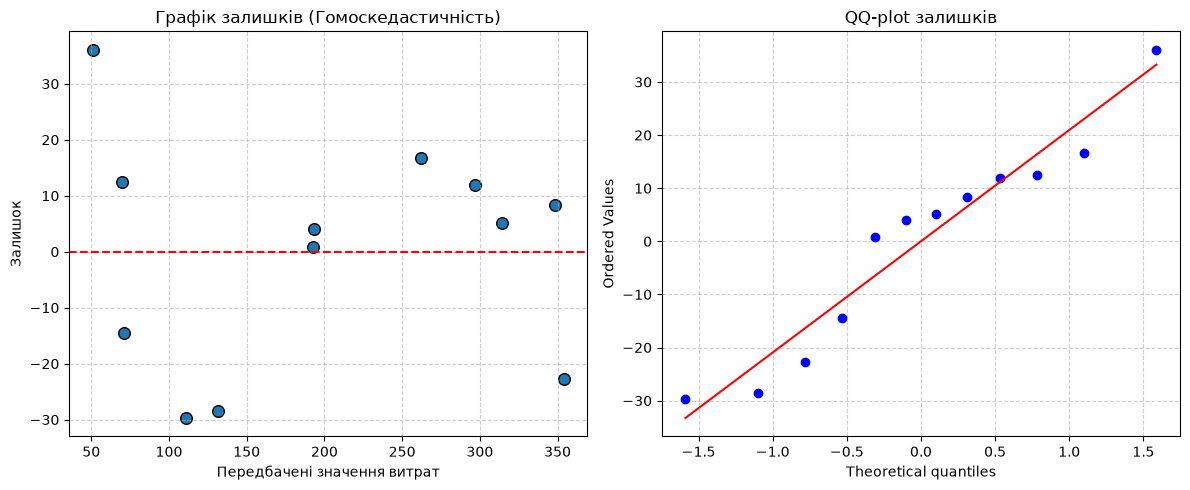

--- Завдання 5. Критерій Шапіро-Вілка ---
Stat = 0.9349, p-value = 0.4347


In [4]:
import matplotlib.pyplot as plt
import scipy.stats as stats

# Завдання 5. Діагностика залишків для моделі 1
fitted1 = model1.fittedvalues
residuals1 = model1.resid

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Графік залишків проти передбачених значень
ax1.scatter(fitted1, residuals1, color='tab:blue', edgecolor='k', s=70)
ax1.axhline(0, color='red', linestyle='--')
ax1.set_xlabel("Передбачені значення витрат")
ax1.set_ylabel("Залишок")
ax1.set_title("Графік залишків (Гомоскедастичність)")
ax1.grid(True, linestyle='--', alpha=0.6)

# QQ-plot залишків
stats.probplot(residuals1, dist="norm", plot=ax2)
ax2.set_title("QQ-plot залишків")
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Критерій Шапіро-Вілка на нормальність залишків
shapiro_test = stats.shapiro(residuals1)
print(f"--- Завдання 5. Критерій Шапіро-Вілка ---")
print(f"Stat = {shapiro_test.statistic:.4f}, p-value = {shapiro_test.pvalue:.4f}")

### Відповідь на Завдання 5. Діагностика залишків
* **Гетероскедастичність:** На графіку залишків проти передбачених значень відсутня виражена лійкоподібна форма, розкид приблизно стабільний (гомоскедастичність не спростовується).
* **Нормальність залишків:** За результатами QQ-plot та критерію Шапіро-Вілка ($p\text{-value} > 0.05$), у нас немає підстав відхиляти нульову гіпотезу про нормальний розподіл залишків.

In [5]:
# Завдання 6. Порівняння з простою регресією (лише температура)
X_simple = sm.add_constant(heating["температура"])
model_simple = sm.OLS(y1, X_simple).fit()

print("--- Завдання 6. Порівняння з простою регресією ---")
print(f"Проста регресія (R²): {model_simple.rsquared:.4f}")
print(f"Множинна регресія (Adjusted R²): {model1.rsquared_adj:.4f}")

--- Завдання 6. Порівняння з простою регресією ---
Проста регресія (R²): 0.9679
Множинна регресія (Adjusted R²): 0.9628


### Відповідь на Завдання 6 та контрольні питання
* **Порівняння з простою регресією:** Додавання другого предиктора (вологості) дещо підвищило пояснену частку дисперсії, але оскільки вологість є відносно слабким і незалежним фактором у цьому наборі, приріст Adjusted $R^2$ порівняно з простою регресією по температурі є помірним.

---

### Відповіді на контрольні питання

1. **Чому `sm.add_constant()` обов'язковий крок перед `sm.OLS()`, і що станеться без нього?**
   `sm.add_constant()` додає до матриці предикторів стовпець одиниць для оцінки вільного члена (intercept, $\beta_0$). Якщо його пропустити, регресійна пряма/площина проходитиме примусово через початок координат ($0$), що у більшості практичних задач призводить до значного зміщення та спотворення коефіцієнтів.

2. **У чому коефіцієнт множинної регресії відрізняється від коефіцієнта простої регресії?**
   У множинній регресії кожен коефіцієнт інтерпретується *за інших рівних умов* (контролюючи вплив інших предикторів у моделі), тоді як у простій регресії коефіцієнт враховує повний спільний ефект без урахування інших факторів.

3. **Чому звичайний $R^2$ не може зменшитись при додаванні нового предиктора?**
   Додавання будь-якого додаткового предиктора не може зменшити суму квадратів залишків ($SS_{res}$), оскільки алгоритм МНК просто знайде нульовий коефіцієнт для марного фактора у гіршому випадку. Через це звичайний $R^2$ непридатний для порівняння моделей із різною кількістю змінних, на відміну від Adjusted $R^2$, який містить штраф за кожен новий параметр.

4. **Що означає VIF предиктора $\approx 1$, що таке VIF $> 10$ і що з цим робити?**
   VIF $\approx 1$ означає повну відсутність мультиколінеарності (незалежність предиктора від інших). VIF $> 10$ вказує на критичну мультиколінеарність (сильну кореляцію з іншими предикторами), що робить оцінки коефіцієнтів нестабільними. На практиці це вирішується виключенням однієї з колінеарних змінних або їх об'єднанням.